## 1. Dataset Inspection

We use the D1 bacterial time-lapse dataset in Cell Tracking Challenge
(CTC) format. We first inspect frame 0 of sequence 00 alongside its
ground-truth segmentation and tracking annotations to understand the
inputs and reference labels before implementing the pipeline.

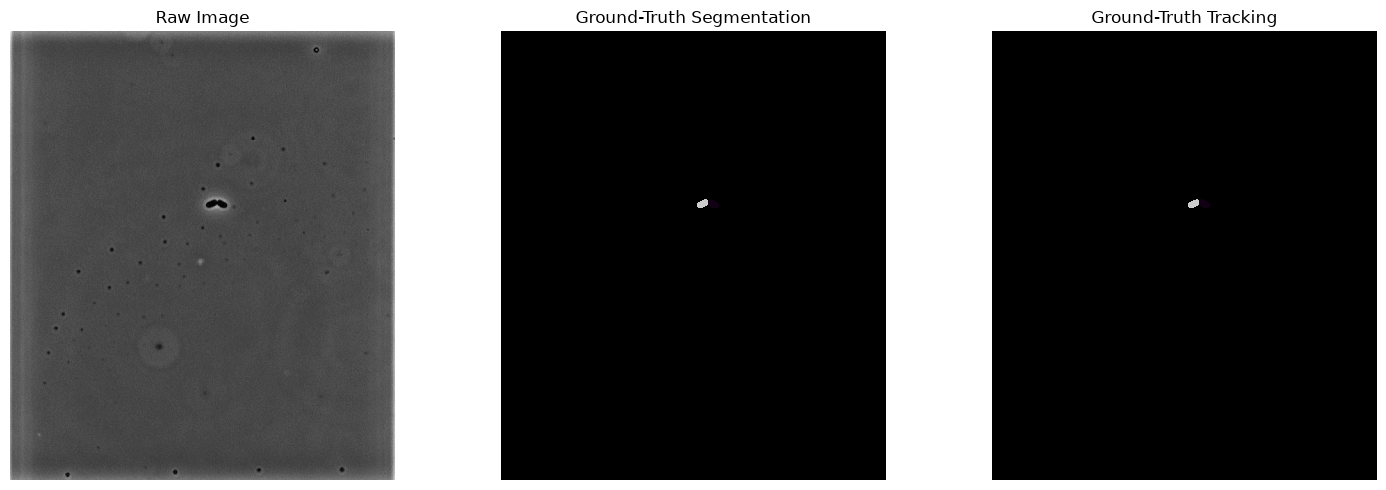

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import tifffile

# Path relative to a notebook located in the notebooks/ directory.
data_dir = Path("../data/ctc_format")

image = tifffile.imread(data_dir / "00/t0000.tif")
segmentation = tifffile.imread(data_dir / "00_GT/SEG/man_seg0000.tif")
tracking = tifffile.imread(data_dir / "00_GT/TRA/man_track0000.tif")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, array, title, cmap in zip(
    axes,
    [image, segmentation, tracking],
    ["Raw Image", "Ground-Truth Segmentation", "Ground-Truth Tracking"],
    ["gray", "nipy_spectral", "nipy_spectral"],
):
    ax.imshow(array, cmap=cmap, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Interpretation

The raw image is the input to the segmentation model. The segmentation
mask identifies individual cells, while the tracking annotations encode
cell identities across frames. Mask colors represent numerical labels,
not biological properties.

A single frame cannot demonstrate tracking or division events;
these require consecutive frames and the lineage information in
`man_track.txt`.

## 2. Inspecting Labels and Lineage Records

We inspect image dimensions, count nonzero cell labels, and load the
reference lineage table. Each row contains a track ID, its first and
last frame, and its parent track ID. A parent ID of 0 indicates that
no parent is recorded.

In [2]:
import numpy as np
import pandas as pd

# Label 0 represents the background.
segmentation_ids = np.unique(segmentation)
segmentation_ids = segmentation_ids[segmentation_ids != 0]

tracking_ids = np.unique(tracking)
tracking_ids = tracking_ids[tracking_ids != 0]

print(f"Image shape: {image.shape}")
print(f"Segmentation shape: {segmentation.shape}")
print(f"Tracking shape: {tracking.shape}")
print(f"Segmented cells in frame 0: {len(segmentation_ids)}")
print(f"Tracked cells in frame 0: {len(tracking_ids)}")

lineage = pd.read_csv(
    data_dir / "00_GT/TRA/man_track.txt",
    sep=r"\s+",
    header=None,
    names=["track_id", "start_frame", "end_frame", "parent_id"],
)

print(f"\nTotal tracks in sequence 00: {len(lineage)}")
display(lineage.head(10))

Image shape: (1094, 938)
Segmentation shape: (1094, 938)
Tracking shape: (1094, 938)
Segmented cells in frame 0: 2
Tracked cells in frame 0: 2

Total tracks in sequence 00: 4918


,track_id,start_frame,end_frame,parent_id
0,1,799,799,0
1,2,799,799,0
2,3,795,798,0
3,4,795,797,0
4,5,792,799,0
5,6,791,799,0
6,7,790,791,0
7,8,789,790,0
8,9,785,799,0
9,10,783,783,0


## 3. Inspecting Temporal Order and Division Annotations

Track IDs do not necessarily follow chronological order. We sort tracks
by their starting frame and inspect records with a nonzero parent ID
to identify annotated parent–daughter relationships.

In [3]:
# Inspect the earliest tracks.
display(
    lineage.sort_values(["start_frame", "track_id"]).head(10)
)

# Inspect tracks with a recorded parent.
daughter_tracks = lineage[lineage["parent_id"] != 0]

print(f"Tracks with a recorded parent: {len(daughter_tracks)}")
print(f"Distinct recorded parents: {daughter_tracks['parent_id'].nunique()}")

display(
    daughter_tracks.sort_values(["start_frame", "parent_id"]).head(10)
)

,track_id,start_frame,end_frame,parent_id
22,23,0,73,0
2101,2102,0,51,0
2102,2103,52,122,2102
3715,3716,52,146,2102
23,24,74,132,23
1206,1207,74,168,23
2103,2104,123,199,2103
3056,3057,123,203,2103
24,25,133,212,24
733,734,133,206,24


Tracks with a recorded parent: 4896
Distinct recorded parents: 2448


,track_id,start_frame,end_frame,parent_id
2102,2103,52,122,2102
3715,3716,52,146,2102
23,24,74,132,23
1206,1207,74,168,23
2103,2104,123,199,2103
3056,3057,123,203,2103
24,25,133,212,24
733,734,133,206,24
3716,3717,147,210,3716
4283,4284,147,210,3716


## 4. Visualizing an Annotated Division

Track 2102 ends at frame 51. Its daughters, tracks 2103 and 3716,
start at frame 52. We highlight their reference tracking masks on
the raw images to inspect this annotated division.

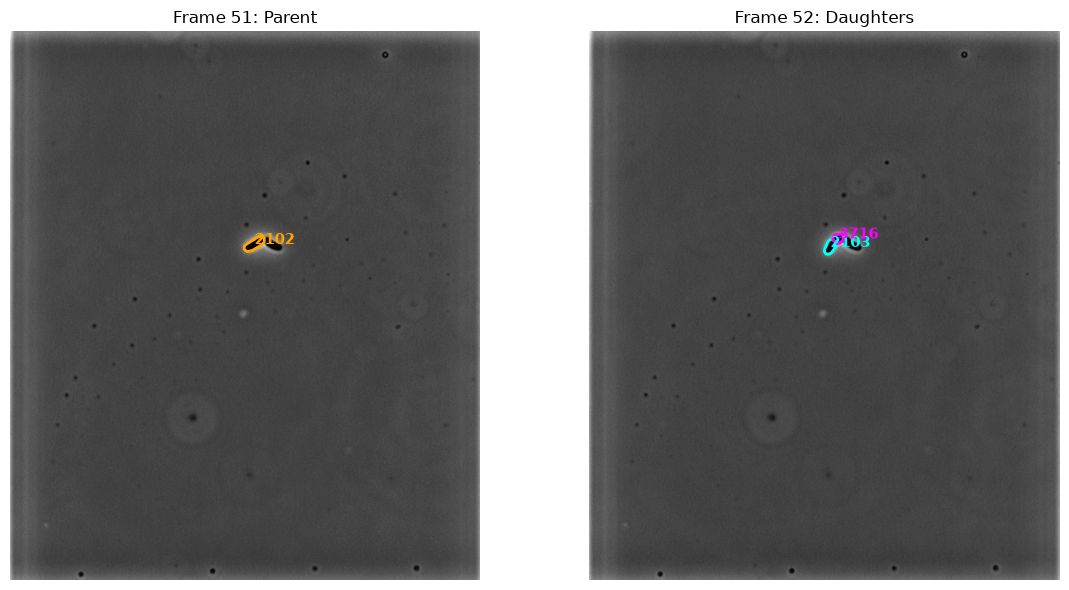

In [4]:
parent_id = 2102
daughter_ids = [2103, 3716]
frames = [51, 52]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, frame in zip(axes, frames):
    raw = tifffile.imread(data_dir / f"00/t{frame:04d}.tif")
    labels = tifffile.imread(
        data_dir / f"00_GT/TRA/man_track{frame:04d}.tif"
    )

    ax.imshow(raw, cmap="gray")

    highlighted_ids = [parent_id] if frame == 51 else daughter_ids
    colors = ["orange"] if frame == 51 else ["cyan", "magenta"]

    for cell_id, color in zip(highlighted_ids, colors):
        mask = labels == cell_id

        if mask.any():
            ax.contour(mask, levels=[0.5], colors=[color], linewidths=2)
            y, x = np.argwhere(mask).mean(axis=0)
            ax.text(
                x, y, str(cell_id),
                color=color, fontsize=11, weight="bold"
            )

    ax.set_title(
        f"Frame {frame}: "
        + ("Parent" if frame == 51 else "Daughters")
    )
    ax.axis("off")

plt.tight_layout()
plt.show()